# 42c. 검사 비율별 Precision · Recall · F1 + 분류 지표

점수 높은 순으로 평가 대상 샷의 r%만 검사할 때 (r = 0.5 ~ 30%)
- **Recall** = 잡은 불량 / 전체 불량, **Precision** = 검사한 샷 중 불량, F1, 무작위 검사 대비 배수, 가스·미성형 몇 개 중 몇 개
- 무작위 검사면 Recall = 검사 비율, Precision = 불량률 → 그래프의 점선

비교 모델
| 제품 | 모델 | 비고 |
|---|---|---|
| CN7 | 최종 모델 | 채택 모델 |
| CN7 | 경보 + std4 흔들림 (38번) | 가스 개선 경향, 순열 p 0.25 → 참고용 |
| RG3 | 최종 모델 | 비지도 |
| RG3 | 가스 전용 RF (37·39번) | Run 하나씩 빼고 검증, 순열 p 0.007 |

**준비**: 20b 실행(R6 제외 반영). RG3 가스 RF는 학습이 들어가서 1~2분 걸림

In [1]:
import pandas as pd
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20)
import inspect_curve as IC
import os; os.makedirs('./outputs/inspect_curve', exist_ok=True)

## CN7

===== CN7 · 최종 모델 =====


,모델,검사 비율,검사 샷,불량,Precision,Recall,F1,Precision 최대(불량수/검사샷),정규화 Precision,무작위 대비(배),무작위 기대 불량,평가 샷,가스,미성형
0,최종 모델,0.5%,10,3/15,0.300,0.200,0.240,1.000,0.300,39.480,0.1,1974,0/11,3/4
1,최종 모델,1%,20,3/15,0.150,0.200,0.171,0.750,0.200,19.740,0.2,1974,0/11,3/4
2,최종 모델,2%,40,3/15,0.075,0.200,0.109,0.375,0.200,9.870,0.3,1974,0/11,3/4
3,최종 모델,3%,60,3/15,0.050,0.200,0.080,0.250,0.200,6.580,0.4,1974,0/11,3/4
4,최종 모델,5%,99,4/15,0.040,0.267,0.070,0.152,0.267,5.317,0.8,1974,1/11,3/4
5,최종 모델,7%,139,5/15,0.036,0.333,0.065,0.108,0.333,4.734,1.0,1974,2/11,3/4
6,최종 모델,10%,198,5/15,0.025,0.333,0.047,0.076,0.333,3.323,1.5,1974,2/11,3/4
7,최종 모델,15%,297,5/15,0.017,0.333,0.032,0.051,0.333,2.215,2.2,1974,2/11,3/4
8,최종 모델,20%,395,6/15,0.015,0.400,0.029,0.038,0.400,1.999,3.0,1974,3/11,3/4
9,최종 모델,30%,593,6/15,0.010,0.400,0.020,0.025,0.400,1.332,4.5,1974,3/11,3/4


===== CN7 · 경보 + std4 (참고) =====


,모델,검사 비율,검사 샷,불량,Precision,Recall,F1,Precision 최대(불량수/검사샷),정규화 Precision,무작위 대비(배),무작위 기대 불량,평가 샷,가스,미성형
0,경보 + std4 (참고),0.5%,10,3/15,0.300,0.200,0.240,1.000,0.300,39.480,0.1,1974,0/11,3/4
1,경보 + std4 (참고),1%,20,3/15,0.150,0.200,0.171,0.750,0.200,19.740,0.2,1974,0/11,3/4
2,경보 + std4 (참고),2%,40,3/15,0.075,0.200,0.109,0.375,0.200,9.870,0.3,1974,0/11,3/4
3,경보 + std4 (참고),3%,60,3/15,0.050,0.200,0.080,0.250,0.200,6.580,0.4,1974,0/11,3/4
4,경보 + std4 (참고),5%,99,4/15,0.040,0.267,0.070,0.152,0.267,5.317,0.8,1974,1/11,3/4
5,경보 + std4 (참고),7%,139,5/15,0.036,0.333,0.065,0.108,0.333,4.734,1.0,1974,2/11,3/4
6,경보 + std4 (참고),10%,198,8/15,0.040,0.533,0.075,0.076,0.533,5.317,1.5,1974,5/11,3/4
7,경보 + std4 (참고),15%,297,8/15,0.027,0.533,0.051,0.051,0.533,3.545,2.2,1974,5/11,3/4
8,경보 + std4 (참고),20%,395,8/15,0.020,0.533,0.039,0.038,0.533,2.665,3.0,1974,5/11,3/4
9,경보 + std4 (참고),30%,593,9/15,0.015,0.600,0.030,0.025,0.600,1.997,4.5,1974,6/11,3/4


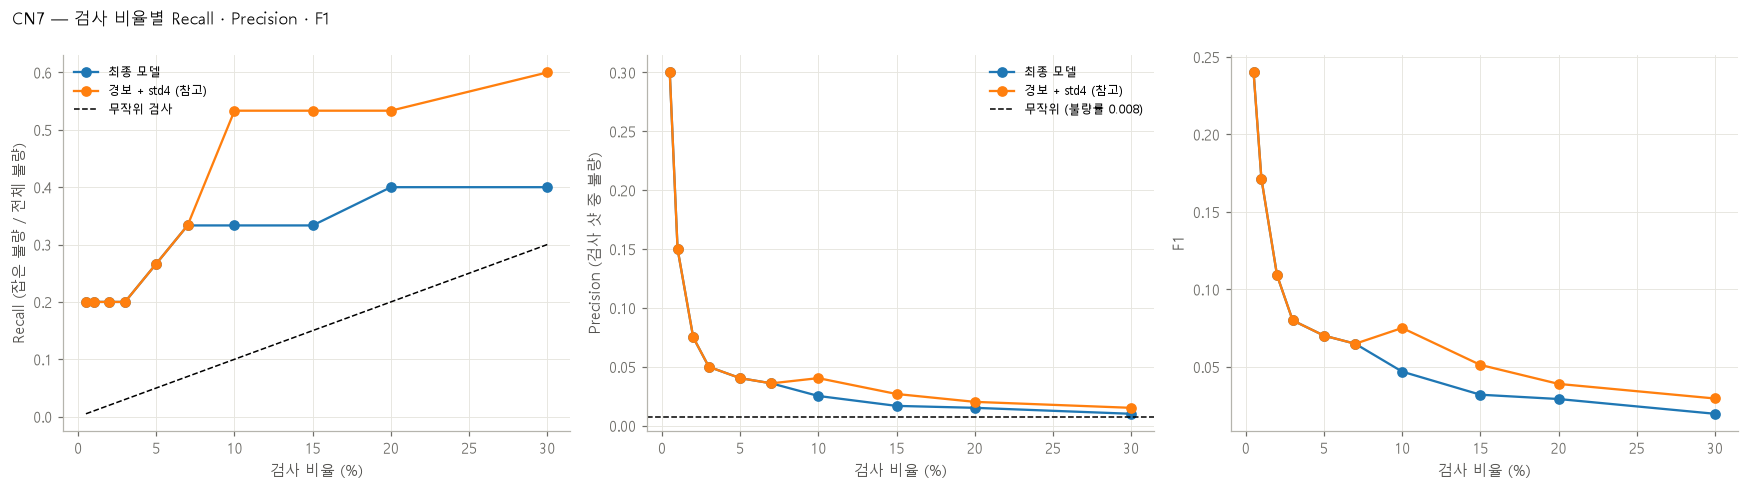

In [2]:
T = {}
lab = IC.load_final('cn7');            T['최종 모델'] = IC.curve(lab, lab['score'].values, name='최종 모델')
lab2, s2 = IC.cn7_alarm_plus_gas_score(10); T['경보 + std4 (참고)'] = IC.curve(lab2, s2, name='경보 + std4 (참고)')
for k, v in T.items():
    print(f'===== CN7 · {k} =====')
    display(v.round(3))
IC.plot_curves(T, 'CN7 — 검사 비율별 Recall · Precision · F1', save='./outputs/inspect_curve/cn7.png')
pd.concat(T.values()).to_csv('./outputs/inspect_curve/cn7.csv', index=False, encoding='utf-8-sig')

## RG3

c:\anaconda\envs\kamp\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\anaconda\envs\kamp\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\anaconda\envs\kamp\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\anaconda\envs\kamp\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.d

===== RG3 · 최종 모델 =====


,모델,검사 비율,검사 샷,불량,Precision,Recall,F1,Precision 최대(불량수/검사샷),정규화 Precision,무작위 대비(배),무작위 기대 불량,평가 샷,가스,미성형
0,최종 모델,0.5%,3,0/25,0.000,0.00,0.000,1.000,0.00,0.000,0.1,591,0/17,0/8
1,최종 모델,1%,6,0/25,0.000,0.00,0.000,1.000,0.00,0.000,0.2,591,0/17,0/8
2,최종 모델,2%,12,0/25,0.000,0.00,0.000,1.000,0.00,0.000,0.5,591,0/17,0/8
3,최종 모델,3%,18,0/25,0.000,0.00,0.000,1.000,0.00,0.000,0.8,591,0/17,0/8
4,최종 모델,5%,30,1/25,0.033,0.04,0.036,0.833,0.04,0.788,1.2,591,1/17,0/8
5,최종 모델,7%,42,1/25,0.024,0.04,0.030,0.595,0.04,0.563,1.8,591,1/17,0/8
6,최종 모델,10%,60,2/25,0.033,0.08,0.047,0.417,0.08,0.788,2.5,591,1/17,1/8
7,최종 모델,15%,89,3/25,0.034,0.12,0.053,0.281,0.12,0.797,3.8,591,2/17,1/8
8,최종 모델,20%,119,4/25,0.034,0.16,0.056,0.210,0.16,0.795,5.0,591,2/17,2/8
9,최종 모델,30%,178,7/25,0.039,0.28,0.069,0.140,0.28,0.930,7.5,591,4/17,3/8


===== RG3 · 가스 전용 RF =====


,모델,검사 비율,검사 샷,불량,Precision,Recall,F1,Precision 최대(불량수/검사샷),정규화 Precision,무작위 대비(배),무작위 기대 불량,평가 샷,가스,미성형
0,가스 전용 RF,0.5%,3,1/25,0.333,0.04,0.071,1.000,0.333,7.880,0.1,591,1/17,0/8
1,가스 전용 RF,1%,6,1/25,0.167,0.04,0.065,1.000,0.167,3.940,0.2,591,1/17,0/8
2,가스 전용 RF,2%,12,2/25,0.167,0.08,0.108,1.000,0.167,3.940,0.5,591,1/17,1/8
3,가스 전용 RF,3%,18,3/25,0.167,0.12,0.140,1.000,0.167,3.940,0.8,591,2/17,1/8
4,가스 전용 RF,5%,30,6/25,0.200,0.24,0.218,0.833,0.240,4.728,1.2,591,5/17,1/8
5,가스 전용 RF,7%,42,9/25,0.214,0.36,0.269,0.595,0.360,5.066,1.8,591,8/17,1/8
6,가스 전용 RF,10%,60,10/25,0.167,0.40,0.235,0.417,0.400,3.940,2.5,591,8/17,2/8
7,가스 전용 RF,15%,89,10/25,0.112,0.40,0.175,0.281,0.400,2.656,3.8,591,8/17,2/8
8,가스 전용 RF,20%,119,10/25,0.084,0.40,0.139,0.210,0.400,1.987,5.0,591,8/17,2/8
9,가스 전용 RF,30%,178,12/25,0.067,0.48,0.118,0.140,0.480,1.594,7.5,591,9/17,3/8


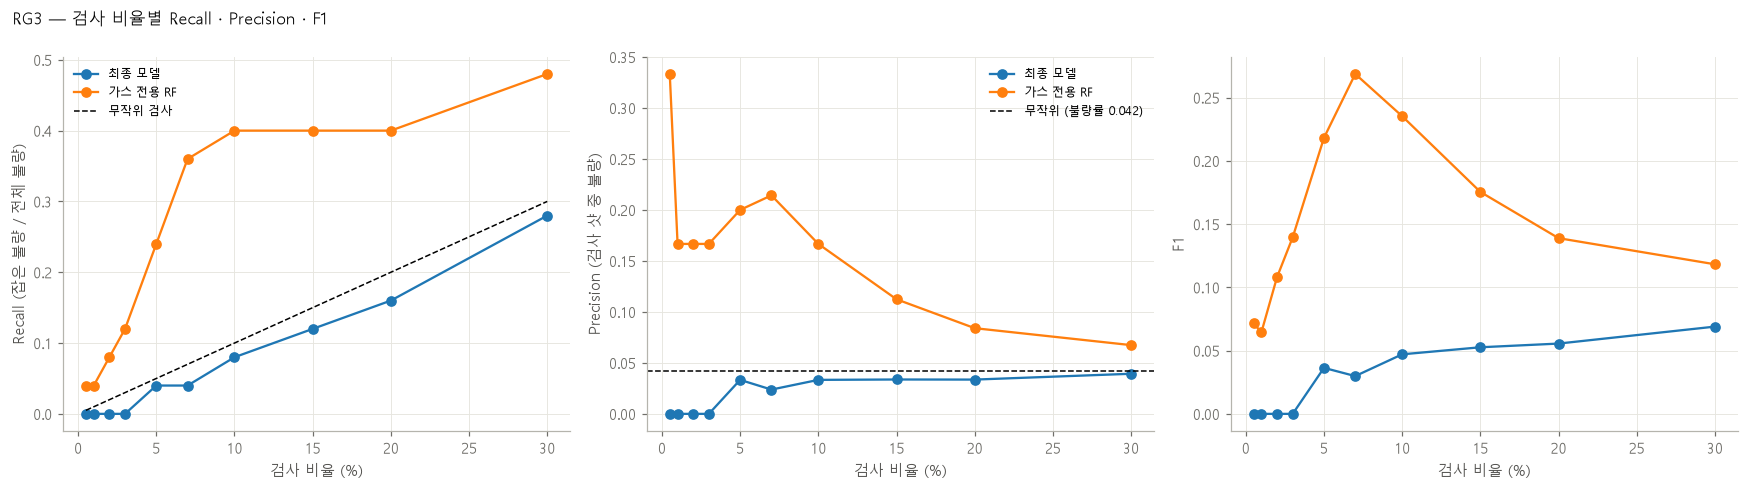

In [3]:
T = {}
lab = IC.load_final('rg3');            T['최종 모델'] = IC.curve(lab, lab['score'].values, name='최종 모델')
lab2, s2 = IC.rg3_gas_rf_score(0);     T['가스 전용 RF'] = IC.curve(lab2, s2, name='가스 전용 RF')
for k, v in T.items():
    print(f'===== RG3 · {k} =====')
    display(v.round(3))
IC.plot_curves(T, 'RG3 — 검사 비율별 Recall · Precision · F1', save='./outputs/inspect_curve/rg3.png')
pd.concat(T.values()).to_csv('./outputs/inspect_curve/rg3.csv', index=False, encoding='utf-8-sig')

## 다른 모델 점수로 보려면
`IC.curve(lab, 점수배열, name='이름')` — lab에 `eval`, `PassOrFail`, `Reason`(또는 `type`) 열이 있으면 어떤 모델이든 가능

## 검사 비율과 무관한 분류 지표 + 2단계 판정
- **R-Precision**: 불량 수만큼만 검사했을 때의 Precision (최대 1, 무작위 = 불량률)
- **Precision@Recall 25·50·75%**: 불량의 그 비율을 잡을 때까지 검사하면 검사 샷 중 불량 비율 / **필요 검사 비율**
- **ROC-AUC**: 불량 하나·정상 하나를 뽑았을 때 불량 점수가 더 높을 확률 (무작위 0.5)
- **2단계 판정**: 상위 10%를 검사 대상으로 고른 뒤, 그 안에서 pct ≥ 0.999면 '불량' 판정 → 검사 대상 안의 혼동행렬 (pct가 있는 최종 모델만)

In [4]:
rows, inner = [], []
for p in ('cn7', 'rg3'):
    lab = IC.load_final(p)
    rows.append({'제품': p, '모델': '최종 모델', **IC.rank_metrics(lab, lab['score'].values)})
    inner.append({'제품': p, **IC.inner_classification(lab, lab['score'].values, lab['pct'].values, budget=0.10, q=0.999)})
lab2, s2 = IC.cn7_alarm_plus_gas_score(10)
rows.append({'제품': 'cn7', '모델': '경보 + std4 (참고)', **IC.rank_metrics(lab2, s2)})
lab3, s3 = IC.rg3_gas_rf_score(0)
rows.append({'제품': 'rg3', '모델': '가스 전용 RF', **IC.rank_metrics(lab3, s3)})
M = pd.DataFrame(rows); display(M.round(3))
print('2단계 판정 (상위 10% 검사 대상 안에서 pct ≥ 0.999 → 불량)')
I = pd.DataFrame(inner); display(I.round(3))
M.to_csv('./outputs/inspect_curve/rank_metrics.csv', index=False, encoding='utf-8-sig')
I.to_csv('./outputs/inspect_curve/inner_classification.csv', index=False, encoding='utf-8-sig')

c:\anaconda\envs\kamp\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\anaconda\envs\kamp\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\anaconda\envs\kamp\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\anaconda\envs\kamp\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.d

,제품,모델,불량 수,R-Precision,ROC-AUC,AP,무작위 기준(불량률),Precision@Recall25%,Recall25% 필요 검사 비율,Precision@Recall50%,Recall50% 필요 검사 비율,Precision@Recall75%,Recall75% 필요 검사 비율
0,cn7,최종 모델,15,0.20,0.569,0.212,0.008,0.043,0.047,0.009,0.431,0.008,0.779
1,rg3,최종 모델,25,0.04,0.554,0.048,0.042,0.041,0.286,0.050,0.440,0.056,0.574
2,cn7,경보 + std4 (참고),15,0.20,0.736,0.220,0.008,0.051,0.040,0.046,0.088,0.011,0.544
3,rg3,가스 전용 RF,25,0.16,0.637,0.118,0.042,0.206,0.058,0.056,0.391,0.051,0.629


2단계 판정 (상위 10% 검사 대상 안에서 pct ≥ 0.999 → 불량)


,제품,검사 대상 샷,그 안의 불량,불량 판정,TP,FP,FN,TN,Precision(판정),Recall(검사 대상 안),F1,Accuracy
0,cn7,198,5,8,3,5,2,188,0.375,0.6,0.462,0.965
1,rg3,60,2,3,0,3,2,55,0.000,0.0,0.000,0.917
